# House Price Prediction



In [12]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
sns.set_theme(style="whitegrid")

## 1. Load data

In [13]:
df = pd.read_csv("house_prices.csv")
print(df.shape); print(df.head()); df.info(); print(df.isnull().sum())

(1812, 11)
  house_id      location  area_sqft  bedrooms  bathrooms  floors  age_years  \
0    H2000  Pantha Chowk     1442.0         2        1.0       1        0.0   
1    H2001        Nowgam     1739.0         3        3.0       1       24.0   
2    H2002         Soura     1887.0         3        2.0       1        0.0   
3    H2003  Pantha Chowk     1273.0         1        1.0       1       12.0   
4    H2004        Nowgam     1660.0         2        1.0       2        NaN   

   distance_to_city_km parking      furnishing  price_lakhs  
0                  7.0      No  Semi-Furnished        55.77  
1                 21.8     Yes       Furnished        62.22  
2                  6.8     Yes  Semi-Furnished        73.26  
3                 24.8      No     Unfurnished        35.96  
4                  1.3     Yes  Semi-Furnished        68.15  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1812 entries, 0 to 1811
Data columns (total 11 columns):
 #   Column               Non-Null 

## 2. Data cleaning

In [14]:
df = df.drop_duplicates()
df["age_years"] = df["age_years"].fillna(df["age_years"].median())
df["bathrooms"] = df["bathrooms"].fillna(df["bathrooms"].mode()[0])
df["furnishing"] = df["furnishing"].fillna(df["furnishing"].mode()[0])
# Outliers: remove unrealistic areas using the IQR rule
q1, q3 = df["area_sqft"].quantile([.25, .75]); iqr = q3 - q1
upper = q3 + 1.5 * iqr
print("Outliers removed:", (df["area_sqft"] > upper).sum())
df = df[df["area_sqft"] <= upper].reset_index(drop=True)
df.to_csv("house_prices_cleaned.csv", index=False)
print("Clean shape:", df.shape)

Outliers removed: 10
Clean shape: (1790, 11)


## 3. Exploratory data analysis

In [15]:
print(df.describe().round(2))

       area_sqft  bedrooms  bathrooms   floors  age_years  \
count    1790.00   1790.00    1790.00  1790.00    1790.00   
mean     1507.13      2.75       2.30     1.82      18.87   
std       514.03      1.09       1.09     0.67      11.50   
min       450.00      1.00       1.00     1.00       0.00   
25%      1133.00      2.00       1.00     1.00       9.00   
50%      1491.00      3.00       2.00     2.00      19.00   
75%      1867.00      3.00       3.00     2.00      28.00   
max      2971.00      6.00       5.00     3.00      39.00   

       distance_to_city_km  price_lakhs  
count              1790.00      1790.00  
mean                 13.10        66.82  
std                   7.05        26.91  
min                   1.00        12.06  
25%                   6.90        47.80  
50%                  13.20        63.33  
75%                  19.40        81.76  
max                  25.00       187.50  


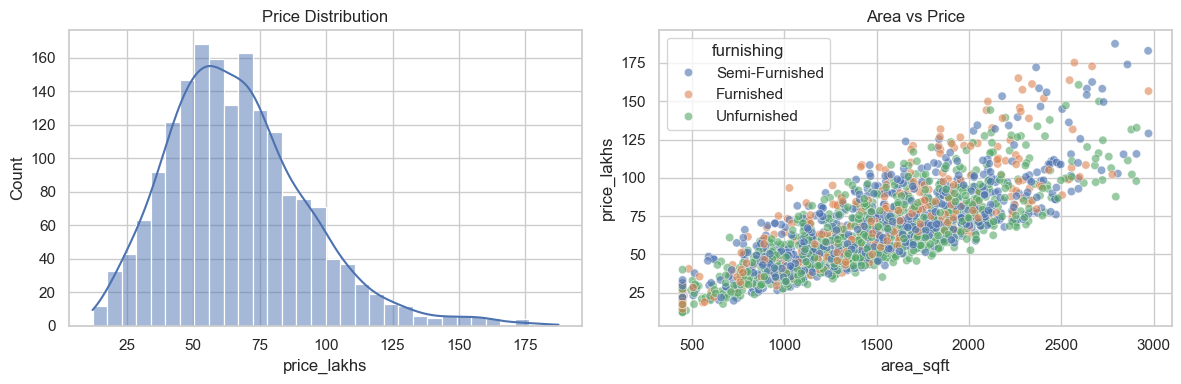

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))
sns.histplot(df["price_lakhs"], kde=True, ax=ax[0], color="#4C72B0"); ax[0].set_title("Price Distribution")
sns.scatterplot(data=df, x="area_sqft", y="price_lakhs", hue="furnishing", alpha=.6, ax=ax[1])
ax[1].set_title("Area vs Price"); plt.tight_layout(); plt.savefig("price_vs_area.png", dpi=120); plt.show()

In [ ]:
order = df.groupby("location")["price_lakhs"].median().sort_values().index
plt.figure(figsize=(10,4)); sns.boxplot(data=df, x="location", y="price_lakhs", order=order)
plt.xticks(rotation=35); plt.title("Price by Location"); plt.tight_layout()
plt.savefig("price_by_location.png", dpi=120); plt.show()

In [ ]:
plt.figure(figsize=(7,5))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap"); plt.tight_layout(); plt.savefig("correlation_heatmap.png", dpi=120); plt.show()

## 4. Model building

In [8]:
X = pd.get_dummies(df.drop(columns=["house_id", "price_lakhs"]), drop_first=True)
y = df["price_lakhs"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
models = {"Linear Regression": LinearRegression(),
          "Random Forest": RandomForestRegressor(n_estimators=250, random_state=42, n_jobs=-1),
          "Gradient Boosting": GradientBoostingRegressor(random_state=42)}
res = {}
for name, m in models.items():
    m.fit(X_tr, y_tr); p = m.predict(X_te)
    res[name] = {"R2": r2_score(y_te, p), "MAE (lakhs)": mean_absolute_error(y_te, p),
                 "RMSE (lakhs)": np.sqrt(mean_squared_error(y_te, p)),
                 "CV R2": cross_val_score(m, X, y, cv=5, scoring="r2").mean()}
res = pd.DataFrame(res).T.round(3); print(res)
res.to_csv("model_comparison.csv")

                      R2  MAE (lakhs)  RMSE (lakhs)  CV R2
Linear Regression  0.954        4.377         5.695  0.947
Random Forest      0.939        4.947         6.535  0.938
Gradient Boosting  0.958        4.232         5.461  0.961


## 5. Feature importance & prediction

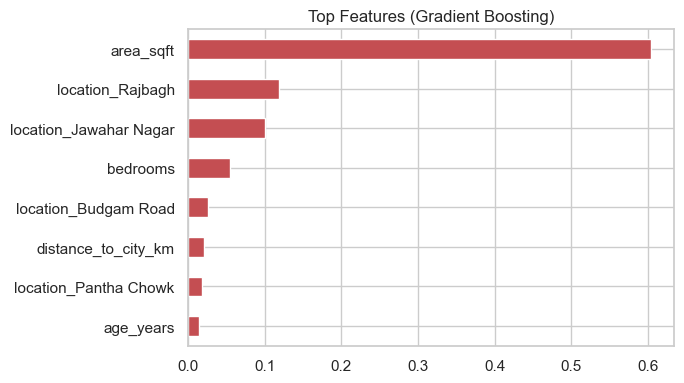

In [9]:
best = models[res["R2"].idxmax()]
imp = pd.Series(best.feature_importances_ if hasattr(best, "feature_importances_") else np.abs(best.coef_),
                index=X.columns).nlargest(8)
imp.sort_values().plot.barh(figsize=(7,4), color="#C44E52"); plt.title(f"Top Features ({res['R2'].idxmax()})")
plt.tight_layout(); plt.savefig("feature_importance.png", dpi=120); plt.show()

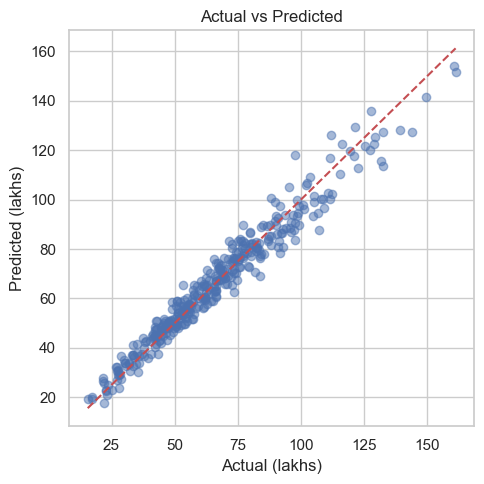

In [10]:
pred = best.predict(X_te)
plt.figure(figsize=(5,5)); plt.scatter(y_te, pred, alpha=.5)
lim = [y_te.min(), y_te.max()]; plt.plot(lim, lim, "r--")
plt.xlabel("Actual (lakhs)"); plt.ylabel("Predicted (lakhs)"); plt.title("Actual vs Predicted")
plt.tight_layout(); plt.savefig("actual_vs_predicted.png", dpi=120); plt.show()

In [11]:
# Predict a new house
new = pd.DataFrame([{"location": "Rajbagh", "area_sqft": 1800, "bedrooms": 3, "bathrooms": 2, "floors": 2,
                     "age_years": 5, "distance_to_city_km": 4.0, "parking": "Yes", "furnishing": "Semi-Furnished"}])
new_X = pd.get_dummies(new).reindex(columns=X.columns, fill_value=0)
print(f"Predicted price: Rs {best.predict(new_X)[0]:.1f} lakhs")

Predicted price: Rs 116.8 lakhs
